In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, LIGHT_GRAY = "#0b0b0b", "#c3c2b7"

# Chart style. You only need to set this once per notebook.
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": LIGHT_GRAY, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)

In [4]:
bbref = pd.read_csv("per_game.csv")

print(bbref.shape)
df = pd.DataFrame(bbref)
df.info()

(47, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 22 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Season  47 non-null     object 
 1   FG      47 non-null     float64
 2   FGA     47 non-null     float64
 3   3P      47 non-null     float64
 4   3PA     47 non-null     float64
 5   ORB     47 non-null     float64
 6   DRB     47 non-null     float64
 7   TRB     47 non-null     float64
 8   AST     47 non-null     float64
 9   STL     47 non-null     float64
 10  TOV     47 non-null     float64
 11  PF      47 non-null     float64
 12  PTS     47 non-null     float64
 13  FG%     47 non-null     float64
 14  3P%     47 non-null     float64
 15  Pace    47 non-null     float64
 16  eFG%    47 non-null     float64
 17  TOV%    47 non-null     float64
 18  ORB%    47 non-null     float64
 19  FT/FGA  47 non-null     float64
 20  ORtg    47 non-null     float64
 21  TS%     47 non-null     float64


In [5]:
league = bbref[['Season','Pace','PTS','3PA','ORtg','eFG%','FT/FGA']]

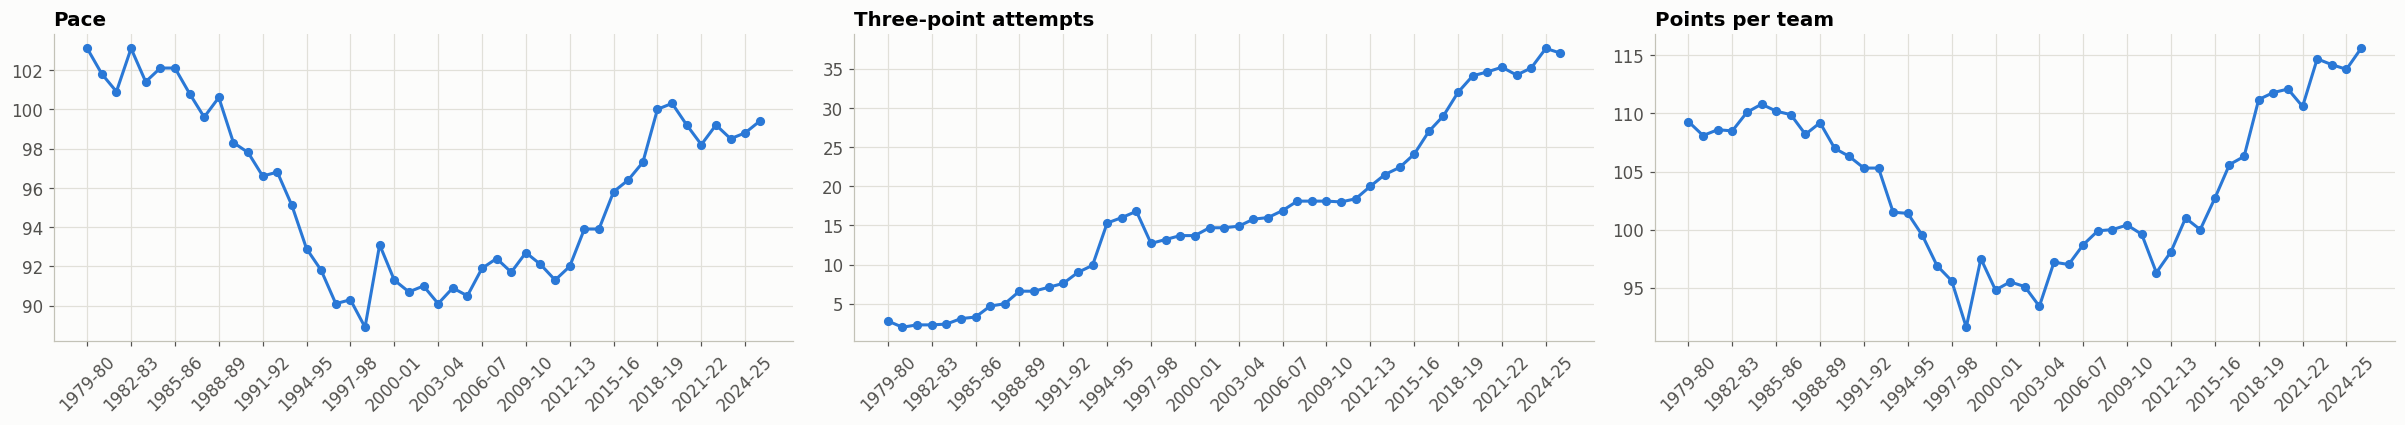

In [6]:
panels = [("Pace", "Pace"), ("3PA", "Three-point attempts"), ("PTS", "Points per team")]
seasons = list(league["Season"])[::-1]
reversed_league = league.iloc[::-1].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(22, 4))
for ax, (col, title) in zip(axes, panels):
    ax.plot(range(len(seasons)), reversed_league[col], color=BLUE, marker="o", markersize=5)
    ax.set_title(title)
    ax.set_xticks(range(0, len(seasons), 3))
    ax.set_xticklabels(seasons[::3], rotation=45)
plt.tight_layout()
plt.show()

In [7]:
col = ["Pace", "3PA"]
corr = df[col].corr()
print(corr)

          Pace       3PA
Pace  1.000000 -0.120481
3PA  -0.120481  1.000000


No to little correlation between Pace and 3PA so create different eras for each stat

Pace Eras
1. 1979-1989 Stable Peak
2. 1989-1999 Steady Decline
3. 1999-2013 Back and Forth
4. 2013-2018 Steady Incline
5. 2018-2025 Back and Forth

In [8]:
pace = bbref[['Season','Pace']].iloc[::-1]
pace["diff"]=pace["Pace"].diff()
print(abs(pace["diff"]).mean())
print(pace)


1.097826086956521
     Season   Pace  diff
46  1979-80  103.1   NaN
45  1980-81  101.8  -1.3
44  1981-82  100.9  -0.9
43  1982-83  103.1   2.2
42  1983-84  101.4  -1.7
41  1984-85  102.1   0.7
40  1985-86  102.1   0.0
39  1986-87  100.8  -1.3
38  1987-88   99.6  -1.2
37  1988-89  100.6   1.0
36  1989-90   98.3  -2.3
35  1990-91   97.8  -0.5
34  1991-92   96.6  -1.2
33  1992-93   96.8   0.2
32  1993-94   95.1  -1.7
31  1994-95   92.9  -2.2
30  1995-96   91.8  -1.1
29  1996-97   90.1  -1.7
28  1997-98   90.3   0.2
27  1998-99   88.9  -1.4
26  1999-00   93.1   4.2
25  2000-01   91.3  -1.8
24  2001-02   90.7  -0.6
23  2002-03   91.0   0.3
22  2003-04   90.1  -0.9
21  2004-05   90.9   0.8
20  2005-06   90.5  -0.4
19  2006-07   91.9   1.4
18  2007-08   92.4   0.5
17  2008-09   91.7  -0.7
16  2009-10   92.7   1.0
15  2010-11   92.1  -0.6
14  2011-12   91.3  -0.8
13  2012-13   92.0   0.7
12  2013-14   93.9   1.9
11  2014-15   93.9   0.0
10  2015-16   95.8   1.9
9   2016-17   96.4   0.6
8   201

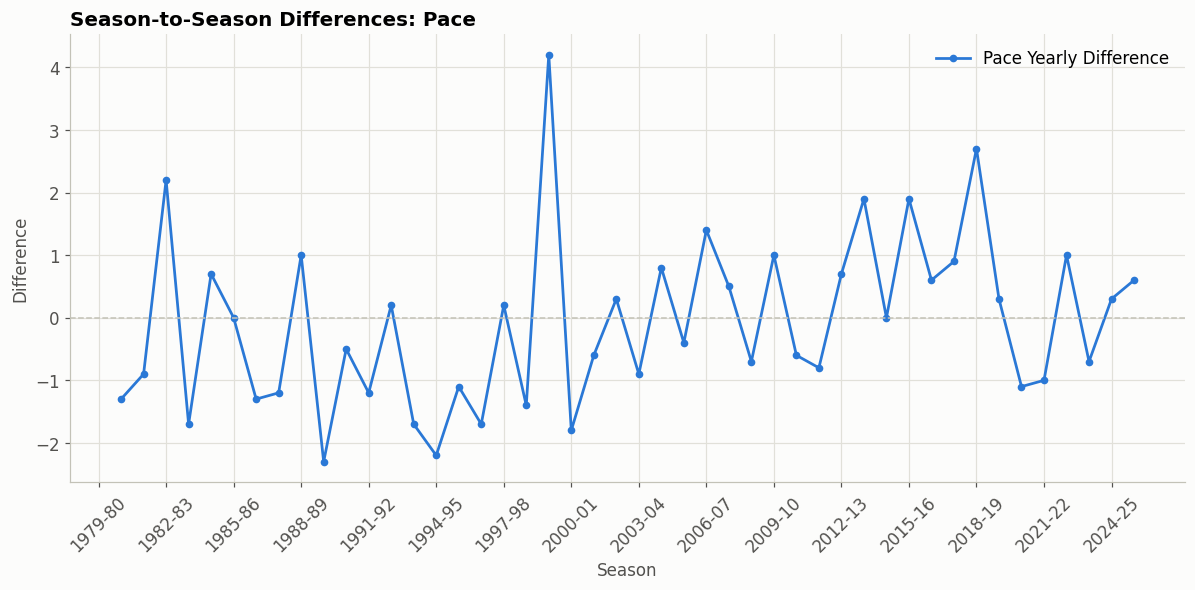

In [9]:

plt.figure(figsize=(11, 5.5))

plt.plot(pace['Season'], pace['diff'], color=BLUE, marker='o', label='Pace Yearly Difference', linewidth=1.8, markersize=4)


plt.axhline(0, color=LIGHT_GRAY, linestyle='--', linewidth=1)
plt.title("Season-to-Season Differences: Pace")
plt.xlabel("Season")
plt.ylabel("Difference")
plt.xticks(range(0, len(pace), 3), pace['Season'].iloc[::3], rotation=45)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

Max: 103.1
Min: 99.6
Mean: 101.55
Range: 3.5
Greatest Diff: 2.1999999999999886
Avg Diff: 1.1444444444444395


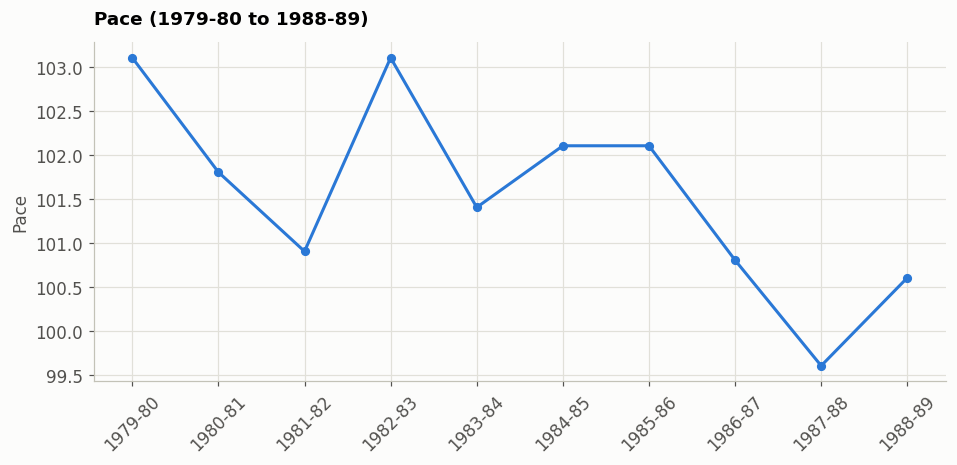

In [10]:
era1 = league.iloc[::-1].reset_index(drop=True).iloc[:10]
seasons1 = list(era1["Season"])

print("Max:", era1['Pace'].max())
print("Min:",era1['Pace'].min())
print("Mean:", era1['Pace'].mean())
print("Range:", era1['Pace'].max()-era1['Pace'].min())
era1["diff"]=era1["Pace"].diff()
print("Greatest Diff:",abs(era1["diff"]).max())
print("Avg Diff:",abs(era1["diff"]).mean())


fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons1)),
    era1["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (1979-80 to 1988-89)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons1)))
ax.set_xticklabels(seasons1, rotation=45)
plt.show()



What if you adjusted the eras by 2 years?
At the edges add 2 years, otherwise add 1 before and 1 after.
A change in min, max, and range indicate an impact

Max: 103.1 New Max: 103.1
Min: 99.6 New Min: 97.8
Mean: 101.55 New Mean: 100.96666666666665
Range: 5.299999999999997 New Range: 5.299999999999997
Greatest Diff: 2.1999999999999886 New Greatest Diff: 2.299999999999997
Avg Diff: 1.1444444444444395 New Avg Diff: 1.1909090909090865


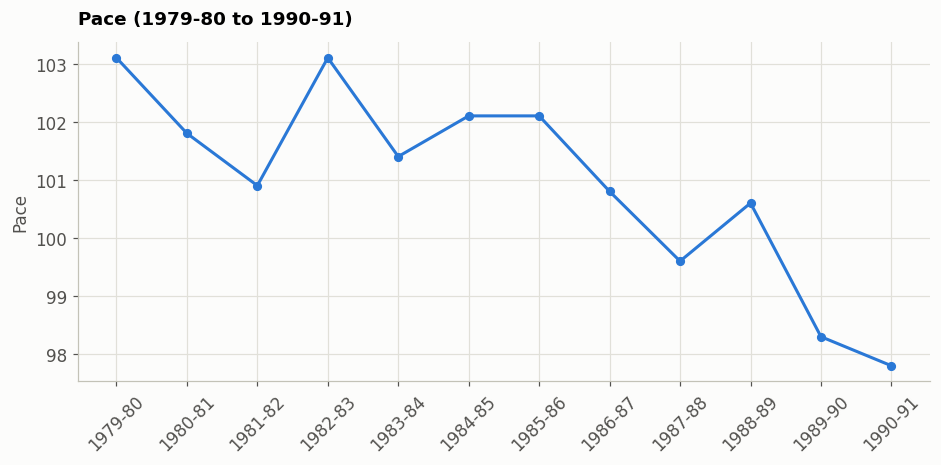

In [26]:
era1_expanded = league.iloc[::-1].reset_index(drop=True).iloc[:12]
seasons1_expanded = list(era1_expanded["Season"])
print("Max:", era1['Pace'].max(), "New Max:", era1_expanded['Pace'].max())
print("Min:",era1['Pace'].min(), "New Min:", era1_expanded['Pace'].min())
print("Mean:", era1['Pace'].mean(), "New Mean:", era1_expanded['Pace'].mean())
print("Range:", era1['Pace'].max()-era1_expanded['Pace'].min(),"New Range:",era1_expanded['Pace'].max()-era1_expanded['Pace'].min())
era1_expanded["diff"]=era1_expanded["Pace"].diff()
print("Greatest Diff:",abs(era1["diff"]).max(), "New Greatest Diff:",abs(era1_expanded["diff"]).max())
print("Avg Diff:",abs(era1["diff"]).mean(),"New Avg Diff:", abs(era1_expanded["diff"]).mean())
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons1_expanded)),
    era1_expanded["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (1979-80 to 1990-91)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons1_expanded)))
ax.set_xticklabels(seasons1_expanded, rotation=45)
plt.show()

Max: 98.3
Min: 88.9
Mean: 93.85999999999999
Range: 9.399999999999991
Greatest Diff: 2.1999999999999886
Avg Diff: 1.1333333333333337


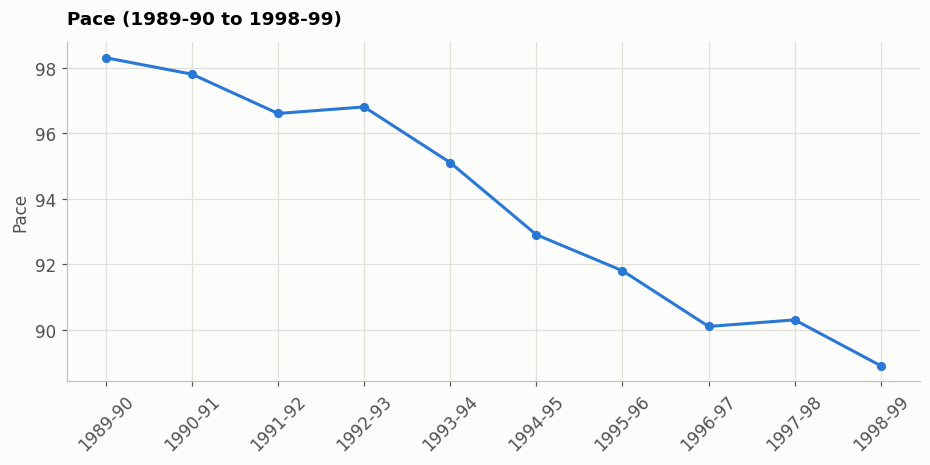

In [12]:
era2=league.iloc[::-1].reset_index(drop=True).iloc[10:20]
seasons2 = list(era2["Season"])

print("Max:", era2['Pace'].max())
print("Min:",era2['Pace'].min())
print("Mean:", era2['Pace'].mean())
print("Range:", era2['Pace'].max()-era2['Pace'].min())
era2["diff"]=era2["Pace"].diff()
print("Greatest Diff:",abs(era2["diff"]).max())
print("Avg Diff:",abs(era2["diff"]).mean())


fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons2)),
    era2["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (1989-90 to 1998-99)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons2)))
ax.set_xticklabels(seasons2, rotation=45)
plt.show()


Max: 98.3 New Max: 100.6
Min: 88.9 New Min: 88.9
Mean: 93.85999999999999 New Mean: 94.3583333333333
Range: 9.399999999999991 New Range: 11.699999999999989
Greatest Diff: 2.1999999999999886 New Greatest Diff: 2.299999999999997
Avg Diff: 1.1333333333333337 New Avg Diff: 1.2666666666666657


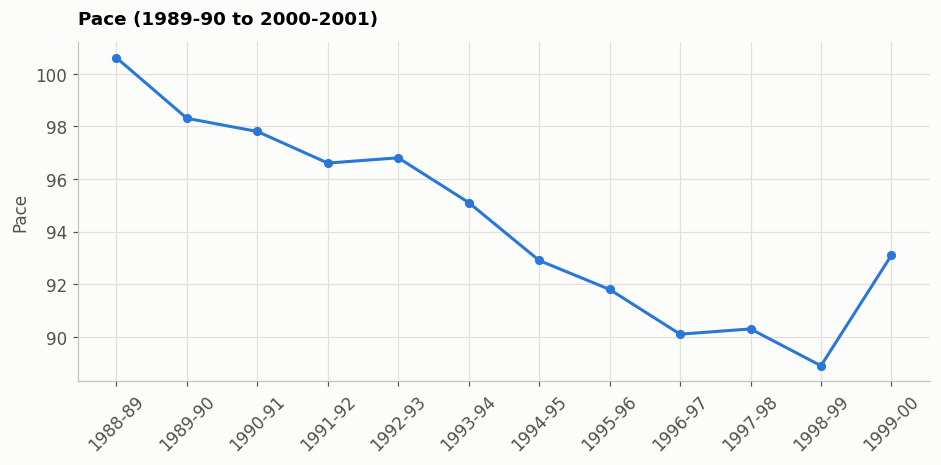

In [31]:
era2_expanded = league.iloc[::-1].reset_index(drop=True).iloc[9:21]
seasons2_expanded = list(era2_expanded["Season"])
print("Max:", era2['Pace'].max(), "New Max:", era2_expanded['Pace'].max())
print("Min:",era2['Pace'].min(), "New Min:", era2_expanded['Pace'].min())
print("Mean:", era2['Pace'].mean(), "New Mean:", era2_expanded['Pace'].mean())
print("Range:", era2['Pace'].max()-era2_expanded['Pace'].min(),"New Range:",era2_expanded['Pace'].max()-era2_expanded['Pace'].min())
era2_expanded["diff"]=era1_expanded["Pace"].diff()
print("Greatest Diff:",abs(era2["diff"]).max(), "New Greatest Diff:",abs(era2_expanded["diff"]).max())
print("Avg Diff:",abs(era2["diff"]).mean(),"New Avg Diff:", abs(era2_expanded["diff"]).mean())
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons2_expanded)),
    era2_expanded["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (1988-89 to 2000-2001)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons2_expanded)))
ax.set_xticklabels(seasons2_expanded, rotation=45)
plt.show()

Max: 93.1
Min: 90.1
Mean: 91.55
Range: 3.0
Greatest Diff: 1.7999999999999972
Avg Diff: 0.8076923076923099


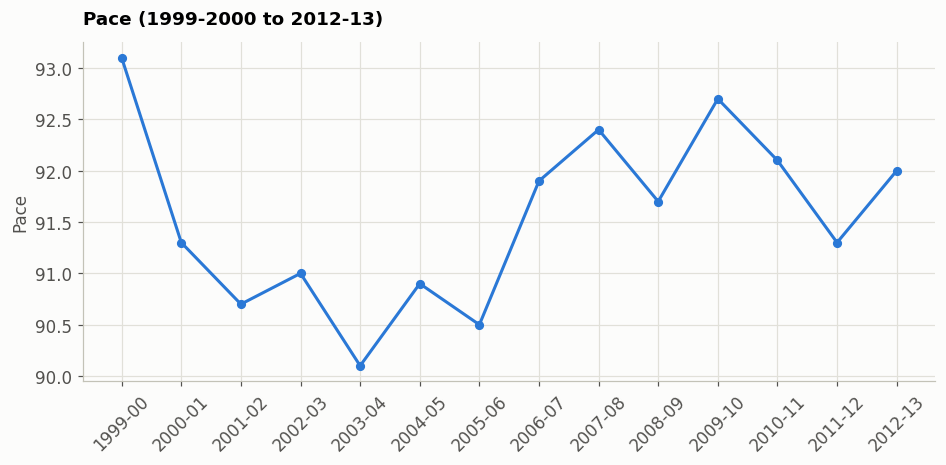

In [13]:
era3=league.iloc[::-1].reset_index(drop=True).iloc[20:34]
seasons3 = list(era3["Season"])

print("Max:", era3['Pace'].max())
print("Min:",era3['Pace'].min())
print("Mean:", era3['Pace'].mean())
print("Range:", era3['Pace'].max()-era3['Pace'].min())
era3["diff"]=era3["Pace"].diff()
print("Greatest Diff:",abs(era3["diff"]).max())
print("Avg Diff:",abs(era3["diff"]).mean())
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons3)),
    era3["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (1999-2000 to 2012-13)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons3)))
ax.set_xticklabels(seasons3, rotation=45)
plt.show()

Max: 93.1 New Max: 93.9
Min: 90.1 New Min: 88.9
Mean: 91.55 New Mean: 91.53125
Range: 3.0 New Range: 5.0
Greatest Diff: 1.7999999999999972 New Greatest Diff: 4.199999999999989
Avg Diff: 0.8076923076923099 New Avg Diff: 1.1066666666666682


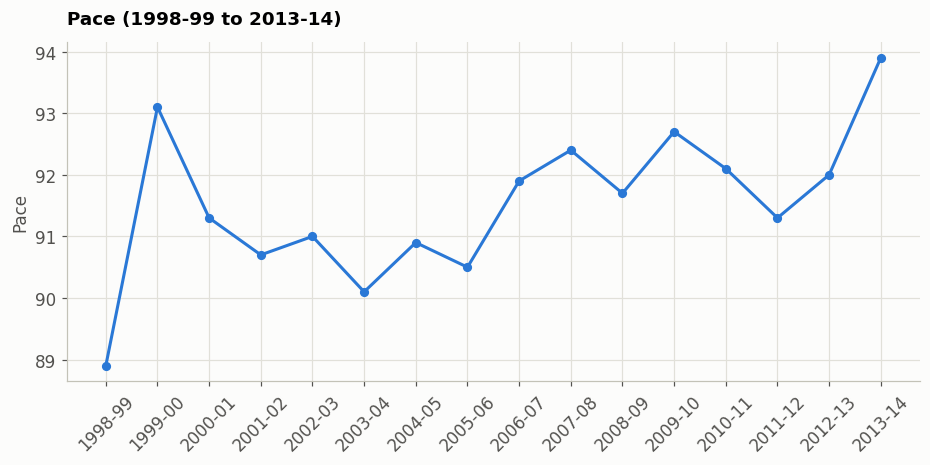

In [33]:
era3_expanded = league.iloc[::-1].reset_index(drop=True).iloc[19:35]
seasons3_expanded = list(era3_expanded["Season"])

print("Max:", era3['Pace'].max(), "New Max:", era3_expanded['Pace'].max())
print("Min:", era3['Pace'].min(), "New Min:", era3_expanded['Pace'].min())
print("Mean:", era3['Pace'].mean(), "New Mean:", era3_expanded['Pace'].mean())
print("Range:", era3['Pace'].max() - era3['Pace'].min(), "New Range:", era3_expanded['Pace'].max() - era3_expanded['Pace'].min())

era3_expanded["diff"] = era3_expanded["Pace"].diff()
print("Greatest Diff:", abs(era3["diff"]).max(), "New Greatest Diff:", abs(era3_expanded["diff"]).max())
print("Avg Diff:", abs(era3["diff"]).mean(), "New Avg Diff:", abs(era3_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons3_expanded)),
    era3_expanded["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (1998-99 to 2013-14)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons3_expanded)))
ax.set_xticklabels(seasons3_expanded, rotation=45)
plt.show()

Max: 97.3
Min: 93.9
Mean: 95.46000000000001
Range: 3.3999999999999915
Greatest Diff: 1.8999999999999915
Avg Diff: 0.8499999999999979


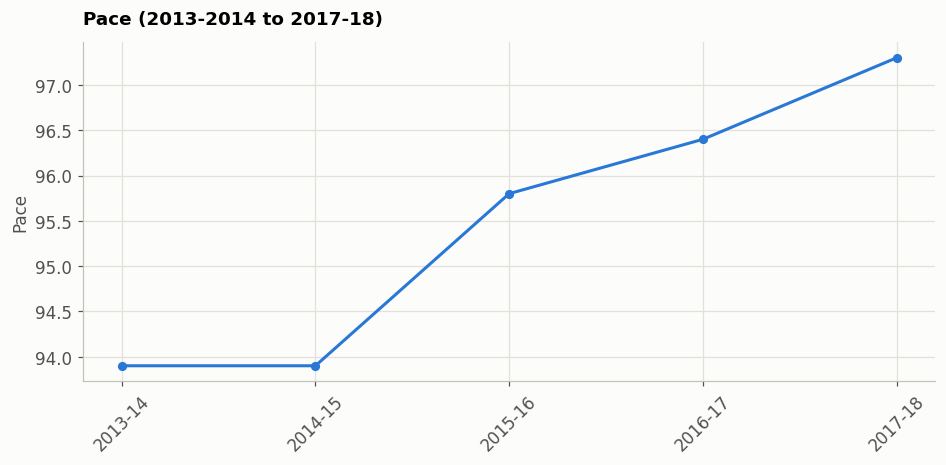

In [14]:
era4=league.iloc[::-1].reset_index(drop=True).iloc[34:39]
seasons4 = list(era4["Season"])

print("Max:", era4['Pace'].max())
print("Min:",era4['Pace'].min())
print("Mean:", era4['Pace'].mean())
print("Range:", era4['Pace'].max()-era4['Pace'].min())
era4["diff"]=era4["Pace"].diff()
print("Greatest Diff:",abs(era4["diff"]).max())
print("Avg Diff:",abs(era4["diff"]).mean())
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons4)),
    era4["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (2013-2014 to 2017-18)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons4)))
ax.set_xticklabels(seasons4, rotation=45)
plt.show()


Max: 97.3 New Max: 100.0
Min: 93.9 New Min: 92.0
Mean: 95.46000000000001 New Mean: 95.61428571428571
Range: 3.3999999999999915 New Range: 8.0
Greatest Diff: 1.8999999999999915 New Greatest Diff: 2.700000000000003
Avg Diff: 0.8499999999999979 New Avg Diff: 1.3333333333333333


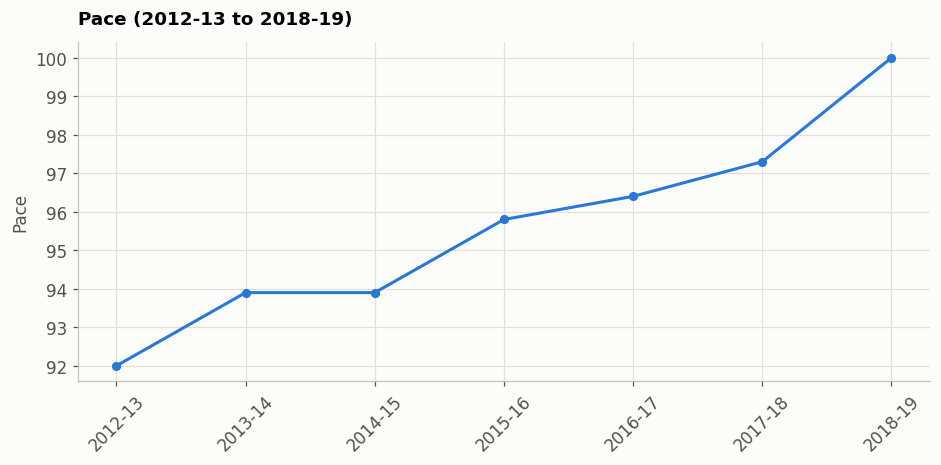

In [34]:
era4_expanded = league.iloc[::-1].reset_index(drop=True).iloc[33:40]
seasons4_expanded = list(era4_expanded["Season"])

print("Max:", era4['Pace'].max(), "New Max:", era4_expanded['Pace'].max())
print("Min:", era4['Pace'].min(), "New Min:", era4_expanded['Pace'].min())
print("Mean:", era4['Pace'].mean(), "New Mean:", era4_expanded['Pace'].mean())
print("Range:", era4['Pace'].max() - era4['Pace'].min(), "New Range:", era4_expanded['Pace'].max() - era4_expanded['Pace'].min())

era4_expanded["diff"] = era4_expanded["Pace"].diff()
print("Greatest Diff:", abs(era4["diff"]).max(), "New Greatest Diff:", abs(era4_expanded["diff"]).max())
print("Avg Diff:", abs(era4["diff"]).mean(), "New Avg Diff:", abs(era4_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons4_expanded)),
    era4_expanded["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (2012-13 to 2018-19)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons4_expanded)))
ax.set_xticklabels(seasons4_expanded, rotation=45)
plt.show()

Max: 100.3
Min: 98.2
Mean: 99.2
Range: 2.0999999999999943
Greatest Diff: 1.0
Avg Diff: -0.0857142857142849


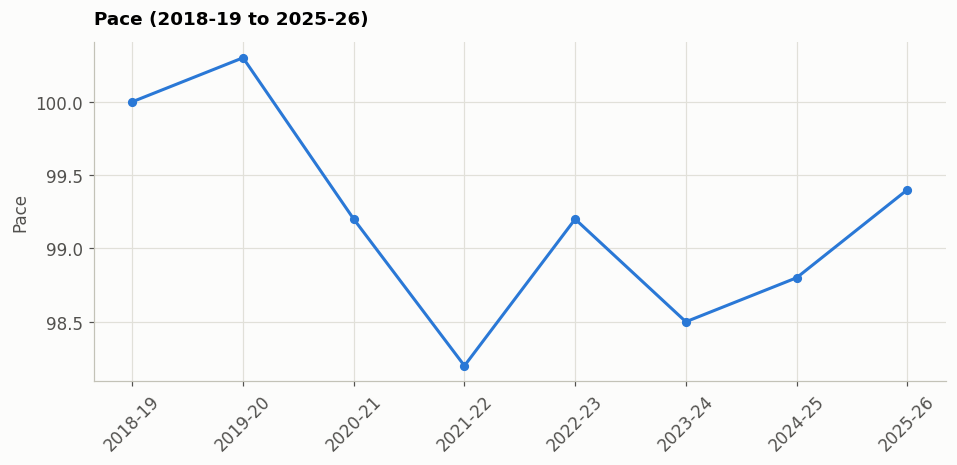

In [15]:
era5=league.iloc[::-1].reset_index(drop=True).iloc[39:]
seasons5 = list(era5["Season"])

print("Max:", era5['Pace'].max())
print("Min:",era5['Pace'].min())
print("Mean:", era5['Pace'].mean())
print("Range:", era5['Pace'].max()-era5['Pace'].min())
era5["diff"]=era5["Pace"].diff()
print("Greatest Diff:", era5["diff"].max())
print("Avg Diff:",era5["diff"].mean())
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons5)),
    era5["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (2018-19 to 2025-26)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons5)))
ax.set_xticklabels(seasons5, rotation=45)
plt.show()

Max: 100.3 New Max: 100.3
Min: 98.2 New Min: 96.4
Mean: 99.2 New Mean: 98.72999999999999
Range: 2.0999999999999943 New Range: 3.8999999999999915
Greatest Diff: 1.0999999999999943 New Greatest Diff: 2.700000000000003
Avg Diff: 0.7142857142857143 New Avg Diff: 0.9555555555555549


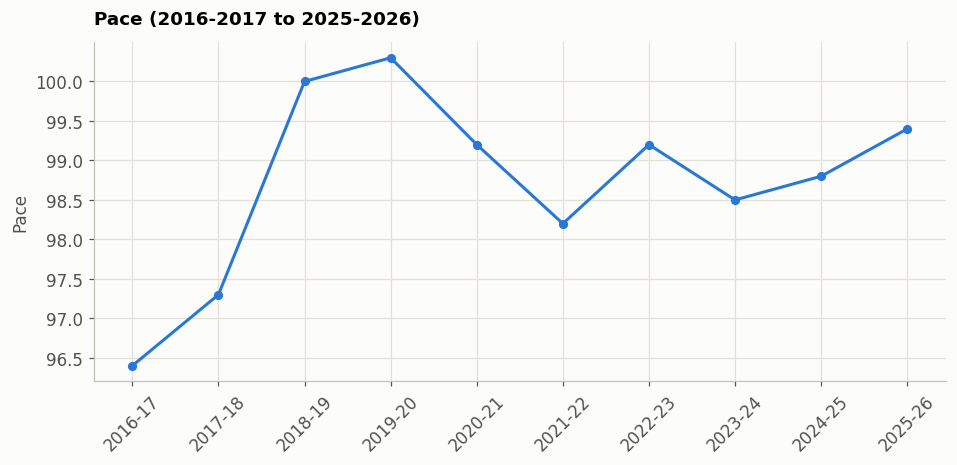

In [35]:
era5_expanded = league.iloc[::-1].reset_index(drop=True).iloc[37:]
seasons5_expanded = list(era5_expanded["Season"])

print("Max:", era5['Pace'].max(), "New Max:", era5_expanded['Pace'].max())
print("Min:", era5['Pace'].min(), "New Min:", era5_expanded['Pace'].min())
print("Mean:", era5['Pace'].mean(), "New Mean:", era5_expanded['Pace'].mean())
print("Range:", era5['Pace'].max() - era5['Pace'].min(), "New Range:", era5_expanded['Pace'].max() - era5_expanded['Pace'].min())

era5_expanded["diff"] = era5_expanded["Pace"].diff()
print("Greatest Diff:", abs(era5["diff"]).max(), "New Greatest Diff:", abs(era5_expanded["diff"]).max())
print("Avg Diff:", abs(era5["diff"]).mean(), "New Avg Diff:", abs(era5_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(seasons5_expanded)),
    era5_expanded["Pace"],
    color=BLUE,
    marker="o",
    markersize=5,
)
ax.set_title("Pace (2016-2017 to 2025-2026)", fontsize=12, pad=12)
ax.set_ylabel("Pace")
ax.set_xticks(range(len(seasons5_expanded)))
ax.set_xticklabels(seasons5_expanded, rotation=45)
plt.show()

3PA Eras
1. 1979-1994 Slight Increase, Low levels
2. 1994-1997 Sudden Spike
3. 1997-2012 Slight Increase, Stagnation
4. 2012-2020 Steady Increase
5. 2020-2025 High Volume

In [16]:
three_pa = bbref[['Season','3PA']].iloc[::-1]
three_pa["diff"]=three_pa["3PA"].diff()
print(abs(three_pa["diff"]).mean())
print(three_pa)

1.0304347826086957
     Season   3PA  diff
46  1979-80   2.8   NaN
45  1980-81   2.0  -0.8
44  1981-82   2.3   0.3
43  1982-83   2.3   0.0
42  1983-84   2.4   0.1
41  1984-85   3.1   0.7
40  1985-86   3.3   0.2
39  1986-87   4.7   1.4
38  1987-88   5.0   0.3
37  1988-89   6.6   1.6
36  1989-90   6.6   0.0
35  1990-91   7.1   0.5
34  1991-92   7.6   0.5
33  1992-93   9.0   1.4
32  1993-94   9.9   0.9
31  1994-95  15.3   5.4
30  1995-96  16.0   0.7
29  1996-97  16.8   0.8
28  1997-98  12.7  -4.1
27  1998-99  13.2   0.5
26  1999-00  13.7   0.5
25  2000-01  13.7   0.0
24  2001-02  14.7   1.0
23  2002-03  14.7   0.0
22  2003-04  14.9   0.2
21  2004-05  15.8   0.9
20  2005-06  16.0   0.2
19  2006-07  16.9   0.9
18  2007-08  18.1   1.2
17  2008-09  18.1   0.0
16  2009-10  18.1   0.0
15  2010-11  18.0  -0.1
14  2011-12  18.4   0.4
13  2012-13  20.0   1.6
12  2013-14  21.5   1.5
11  2014-15  22.4   0.9
10  2015-16  24.1   1.7
9   2016-17  27.0   2.9
8   2017-18  29.0   2.0
7   2018-19  32.0   3

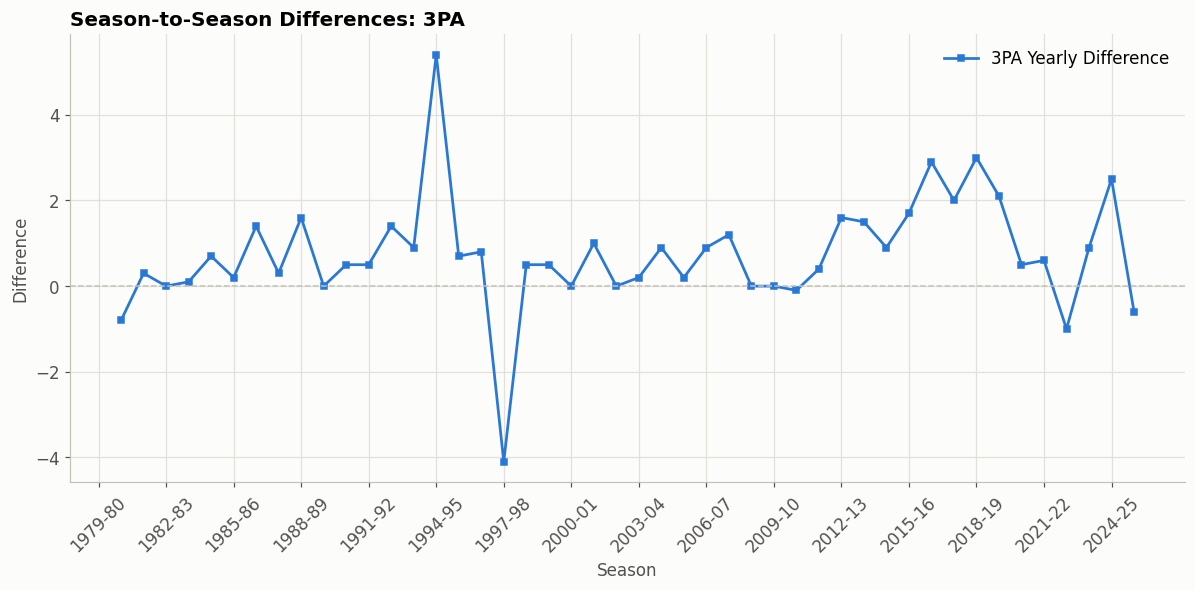

In [17]:
plt.figure(figsize=(11, 5.5))
plt.plot(three_pa['Season'], three_pa['diff'], color=BLUE, marker='s', label='3PA Yearly Difference', linewidth=1.8, markersize=4)
plt.axhline(0, color=LIGHT_GRAY, linestyle='--', linewidth=1)
plt.title("Season-to-Season Differences: 3PA")
plt.xlabel("Season")
plt.ylabel("Difference")
plt.xticks(range(0, len(three_pa), 3), three_pa['Season'].iloc[::3], rotation=45)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

Max: 9.9
Min: 2.0
Mean: 4.980000000000001
Range: 7.9
Greatest Diff: 1.5999999999999996
Avg Diff: 0.6214285714285713


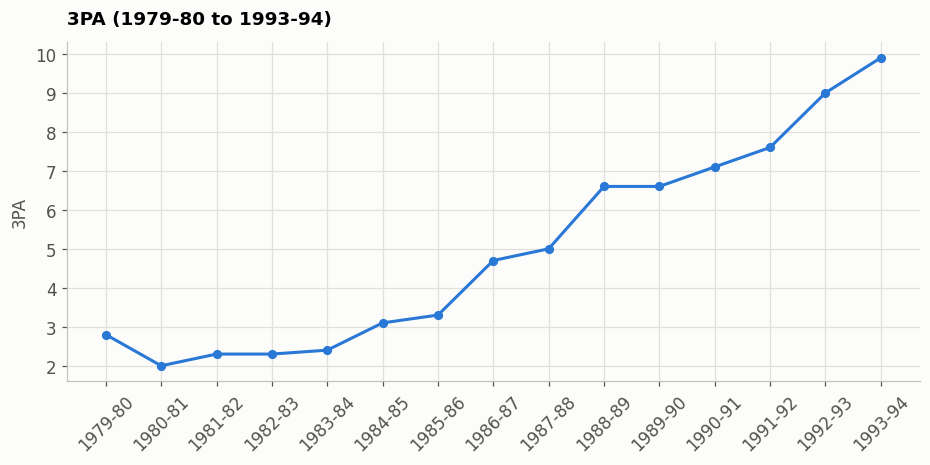

In [18]:
three_pa_era1 = league.iloc[::-1].reset_index(drop=True).iloc[:15]
three_seasons1 = list(three_pa_era1["Season"])

print("Max:", three_pa_era1['3PA'].max())
print("Min:",three_pa_era1['3PA'].min())
print("Mean:", three_pa_era1['3PA'].mean())
print("Range:", three_pa_era1['3PA'].max()-three_pa_era1['3PA'].min())
three_pa_era1["diff"]=three_pa_era1["3PA"].diff()
print("Greatest Diff:",abs(three_pa_era1["diff"]).max())
print("Avg Diff:",abs(three_pa_era1["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons1)), three_pa_era1["3PA"], color=BLUE, marker="o", markersize=5
)
ax.set_title("3PA (1979-80 to 1993-94)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons1)))
ax.set_xticklabels(three_seasons1, rotation=45)
plt.show()


Max: 9.9 New Max: 16.0
Min: 2.0 New Min: 2.0
Mean: 4.980000000000001 New Mean: 6.235294117647059
Range: 7.9 New Range: 14.0
Greatest Diff: 1.5999999999999996 New Greatest Diff: 5.4
Avg Diff: 0.6214285714285713 New Avg Diff: 0.925


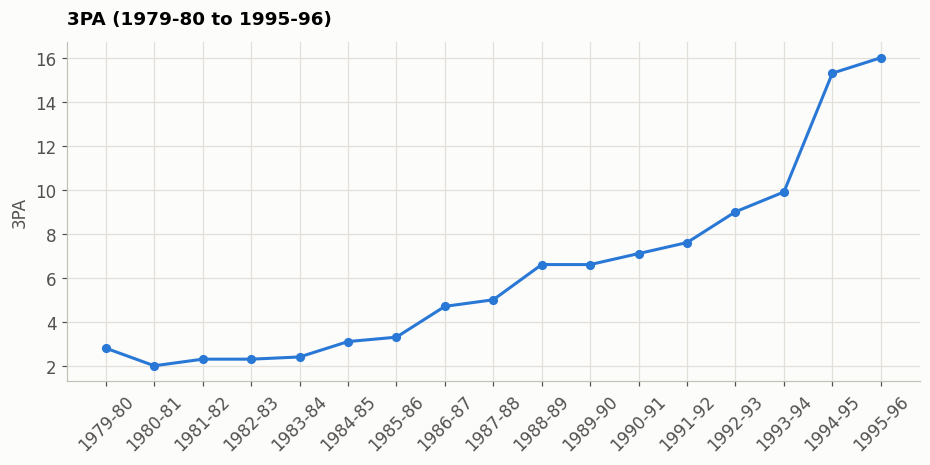

In [37]:
three_pa_era1_expanded = league.iloc[::-1].reset_index(drop=True).iloc[:17]
three_seasons1_expanded = list(three_pa_era1_expanded["Season"])

print("Max:", three_pa_era1['3PA'].max(), "New Max:", three_pa_era1_expanded['3PA'].max())
print("Min:", three_pa_era1['3PA'].min(), "New Min:", three_pa_era1_expanded['3PA'].min())
print("Mean:", three_pa_era1['3PA'].mean(), "New Mean:", three_pa_era1_expanded['3PA'].mean())
print("Range:", three_pa_era1['3PA'].max() - three_pa_era1['3PA'].min(), "New Range:", three_pa_era1_expanded['3PA'].max() - three_pa_era1_expanded['3PA'].min())

three_pa_era1_expanded["diff"] = three_pa_era1_expanded["3PA"].diff()
print("Greatest Diff:", abs(three_pa_era1["diff"]).max(), "New Greatest Diff:", abs(three_pa_era1_expanded["diff"]).max())
print("Avg Diff:", abs(three_pa_era1["diff"]).mean(), "New Avg Diff:", abs(three_pa_era1_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons1_expanded)),
    three_pa_era1_expanded["3PA"],
    color=BLUE,
    marker="o",
    markersize=5
)
ax.set_title("3PA (1979-80 to 1995-96)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons1_expanded)))
ax.set_xticklabels(three_seasons1_expanded, rotation=45)
plt.show()

Max: 16.8
Min: 15.3
Mean: 16.033333333333335
Range: 1.5
Greatest Diff: 0.8000000000000007
Avg Diff: 0.75


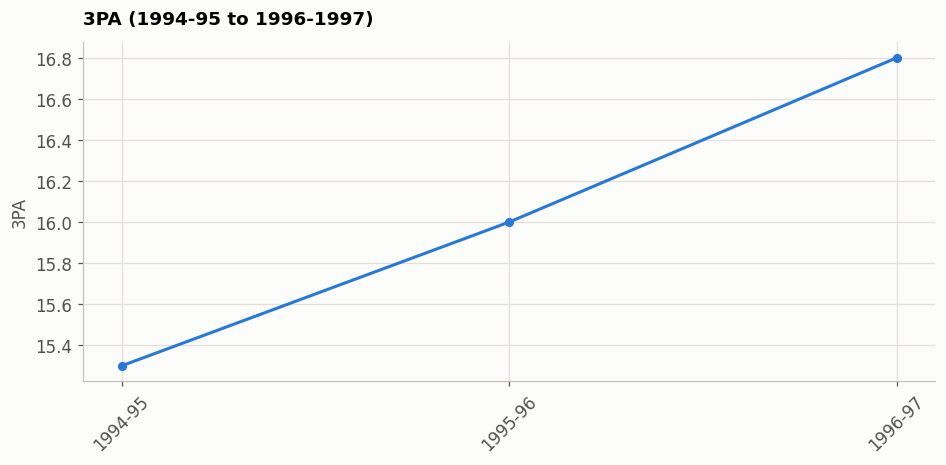

In [19]:
three_pa_era2 = league.iloc[::-1].reset_index(drop=True).iloc[15:18]
three_seasons2 = list(three_pa_era2["Season"])

print("Max:", three_pa_era2['3PA'].max())
print("Min:",three_pa_era2['3PA'].min())
print("Mean:", three_pa_era2['3PA'].mean())
print("Range:", three_pa_era2['3PA'].max()-three_pa_era2['3PA'].min())
three_pa_era2["diff"]=three_pa_era2["3PA"].diff()
print("Greatest Diff:",abs(three_pa_era2["diff"]).max())
print("Avg Diff:",abs(three_pa_era2["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons2)), three_pa_era2["3PA"], color=BLUE, marker="o", markersize=5
)
ax.set_title("3PA (1994-95 to 1996-1997)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons2)))
ax.set_xticklabels(three_seasons2, rotation=45)
plt.show()


Max: 16.8 New Max: 16.8
Min: 15.3 New Min: 9.9
Mean: 16.033333333333335 New Mean: 14.14
Range: 1.5 New Range: 6.9
Greatest Diff: 0.8000000000000007 New Greatest Diff: 5.4
Avg Diff: 0.75 New Avg Diff: 2.7500000000000004


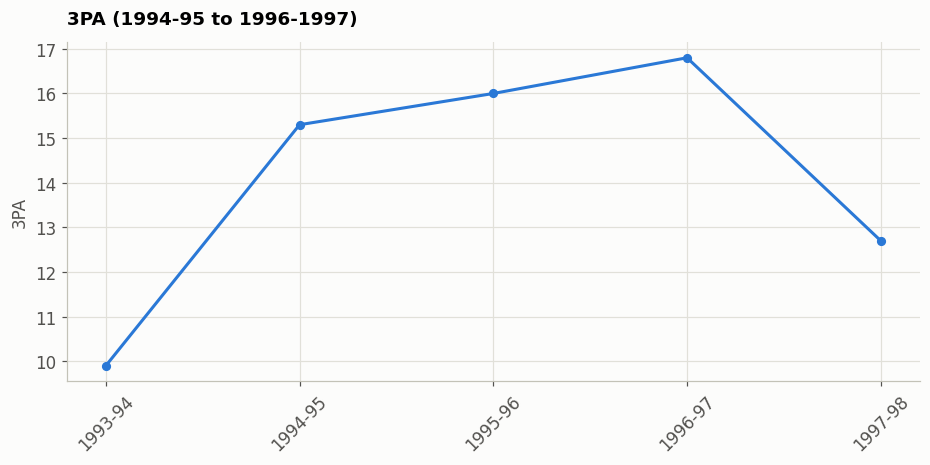

In [38]:
three_pa_era2_expanded = league.iloc[::-1].reset_index(drop=True).iloc[14:19]
three_seasons2_expanded = list(three_pa_era2_expanded["Season"])

print("Max:", three_pa_era2['3PA'].max(), "New Max:", three_pa_era2_expanded['3PA'].max())
print("Min:", three_pa_era2['3PA'].min(), "New Min:", three_pa_era2_expanded['3PA'].min())
print("Mean:", three_pa_era2['3PA'].mean(), "New Mean:", three_pa_era2_expanded['3PA'].mean())
print("Range:", three_pa_era2['3PA'].max() - three_pa_era2['3PA'].min(), "New Range:", three_pa_era2_expanded['3PA'].max() - three_pa_era2_expanded['3PA'].min())

three_pa_era2_expanded["diff"] = three_pa_era2_expanded["3PA"].diff()
print("Greatest Diff:", abs(three_pa_era2["diff"]).max(), "New Greatest Diff:", abs(three_pa_era2_expanded["diff"]).max())
print("Avg Diff:", abs(three_pa_era2["diff"]).mean(), "New Avg Diff:", abs(three_pa_era2_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons2_expanded)),
    three_pa_era2_expanded["3PA"],
    color=BLUE,
    marker="o",
    markersize=5
)
ax.set_title("3PA (1994-95 to 1996-1997)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons2_expanded)))
ax.set_xticklabels(three_seasons2_expanded, rotation=45)
plt.show()

The sudden spike from 1994-1997 was the result of shortening the 3-point line from 23 feet, 9 inches to 22 feet.

Was there also a noticeable difference in PTS, ORtg, eFG%, 3P% during these 3 years?

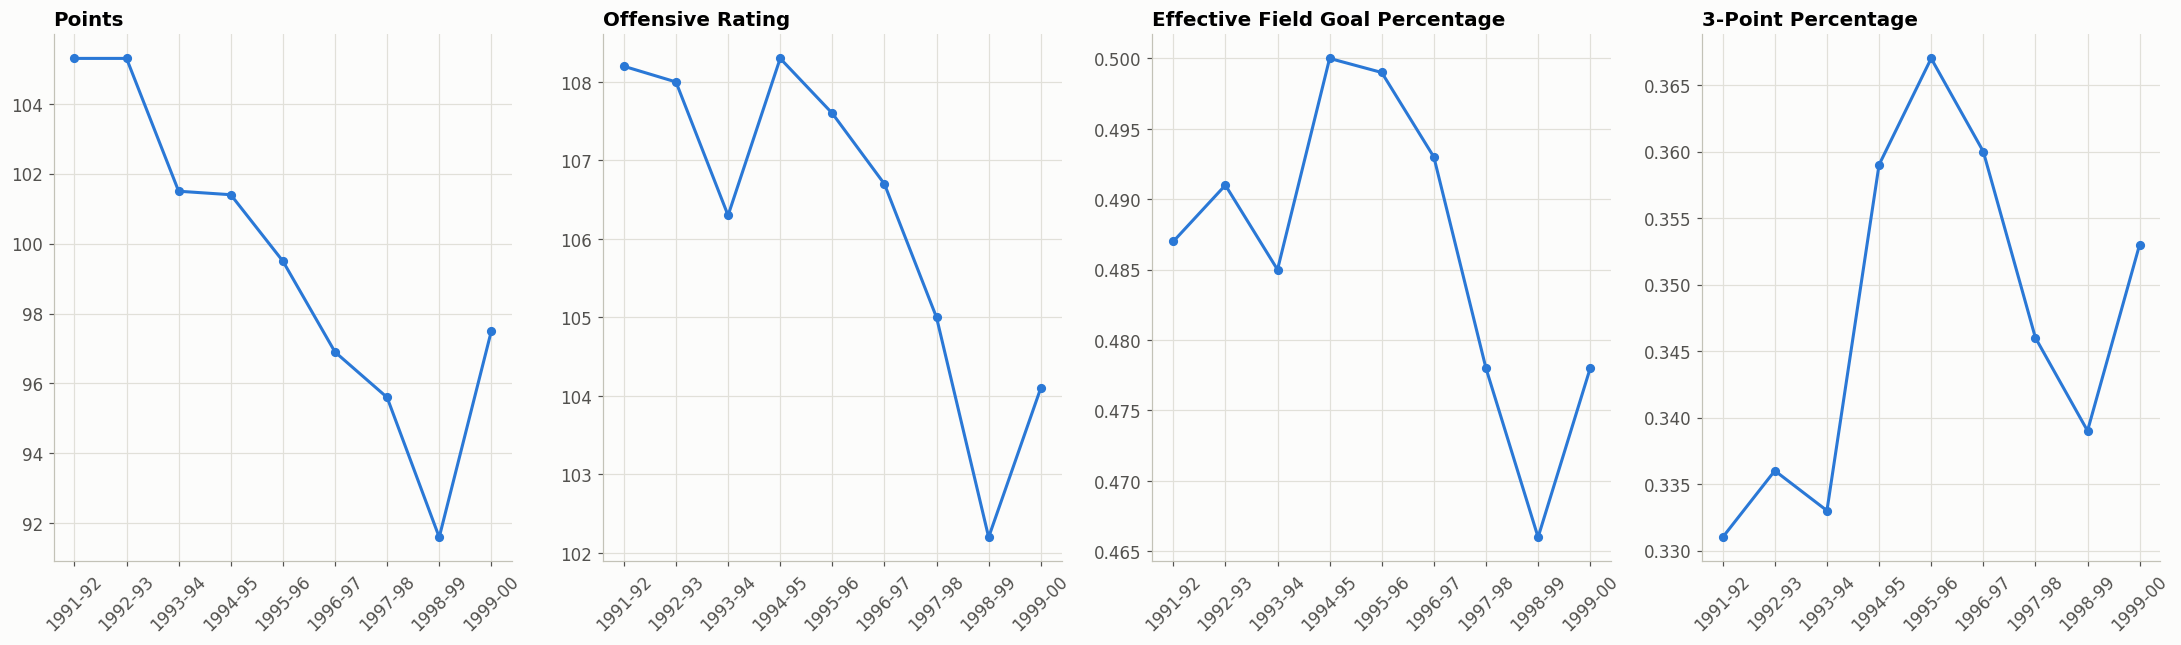

In [20]:
spike_stats = bbref[['Season','PTS','ORtg','eFG%','3P%']]
spike_panel = [("PTS", "Points"), ("ORtg", "Offensive Rating"), ("eFG%", "Effective Field Goal Percentage"), ("3P%","3-Point Percentage")]
spike = spike_stats.iloc[::-1].reset_index(drop=True).iloc[12:21]
spike_seasons = list(spike["Season"])


fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for ax, (col, title) in zip(axes, spike_panel):
    ax.plot(range(len(spike_seasons)), spike[col], color=BLUE, marker="o", markersize=5)
    ax.set_title(title)
    ax.set_xticks(range(0, len(spike_seasons), 1))
    ax.set_xticklabels(spike_seasons[::1], rotation=45)
plt.tight_layout()
plt.show()



Max: 18.4
Min: 12.7
Mean: 15.8
Range: 5.699999999999999
Greatest Diff: 1.2000000000000028
Avg Diff: 0.4214285714285716


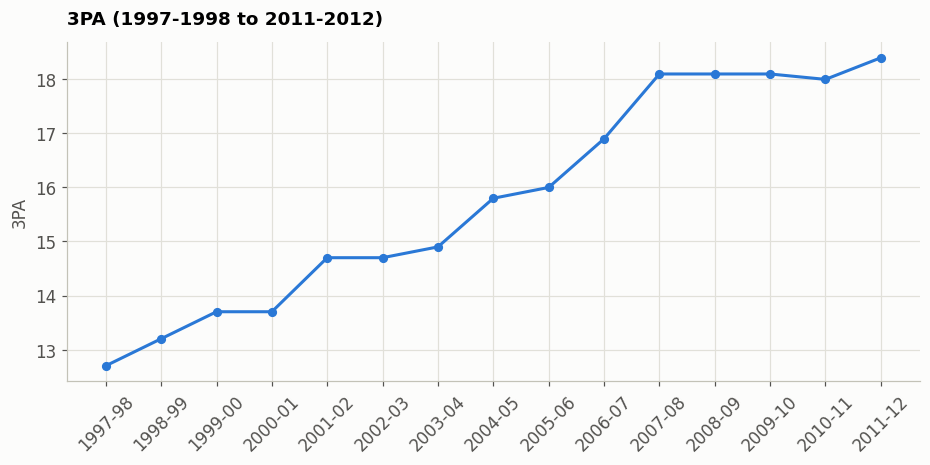

In [42]:
three_pa_era3 = league.iloc[::-1].reset_index(drop=True).iloc[18:33]
three_seasons3 = list(three_pa_era3["Season"])

print("Max:", three_pa_era3['3PA'].max())
print("Min:",three_pa_era3['3PA'].min())
print("Mean:", three_pa_era3['3PA'].mean())
print("Range:", three_pa_era3['3PA'].max()-three_pa_era3['3PA'].min())
three_pa_era3["diff"]=three_pa_era3["3PA"].diff()
print("Greatest Diff:",abs(three_pa_era3["diff"]).max())
print("Avg Diff:",abs(three_pa_era3["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons3)), three_pa_era3["3PA"], color=BLUE, marker="o", markersize=5
)
ax.set_title("3PA (1997-1998 to 2011-2012)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons3)))
ax.set_xticklabels(three_seasons3, rotation=45)
plt.show()


Max: 18.4 New Max: 20.0
Min: 12.7 New Min: 12.7
Mean: 15.8 New Mean: 16.105882352941173
Range: 5.699999999999999 New Range: 7.300000000000001
Greatest Diff: 1.2000000000000028 New Greatest Diff: 4.100000000000001
Avg Diff: 0.4214285714285716 New Avg Diff: 0.7250000000000003


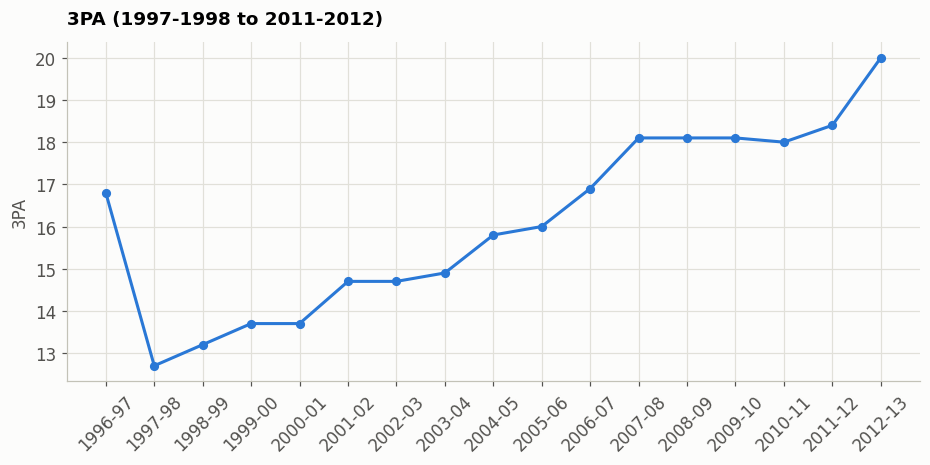

In [43]:
three_pa_era3_expanded = league.iloc[::-1].reset_index(drop=True).iloc[17:34]
three_seasons3_expanded = list(three_pa_era3_expanded["Season"])

print("Max:", three_pa_era3['3PA'].max(), "New Max:", three_pa_era3_expanded['3PA'].max())
print("Min:", three_pa_era3['3PA'].min(), "New Min:", three_pa_era3_expanded['3PA'].min())
print("Mean:", three_pa_era3['3PA'].mean(), "New Mean:", three_pa_era3_expanded['3PA'].mean())
print("Range:", three_pa_era3['3PA'].max() - three_pa_era3['3PA'].min(), "New Range:", three_pa_era3_expanded['3PA'].max() - three_pa_era3_expanded['3PA'].min())

three_pa_era3_expanded["diff"] = three_pa_era3_expanded["3PA"].diff()
print("Greatest Diff:", abs(three_pa_era3["diff"]).max(), "New Greatest Diff:", abs(three_pa_era3_expanded["diff"]).max())
print("Avg Diff:", abs(three_pa_era3["diff"]).mean(), "New Avg Diff:", abs(three_pa_era3_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons3_expanded)),
    three_pa_era3_expanded["3PA"],
    color=BLUE,
    marker="o",
    markersize=5
)
ax.set_title("3PA (1997-1998 to 2011-2012)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons3_expanded)))
ax.set_xticklabels(three_seasons3_expanded, rotation=45)
plt.show()

Max: 34.1
Min: 20.0
Mean: 26.2625
Range: 14.100000000000001
Greatest Diff: 3.0
Avg Diff: 2.0142857142857147


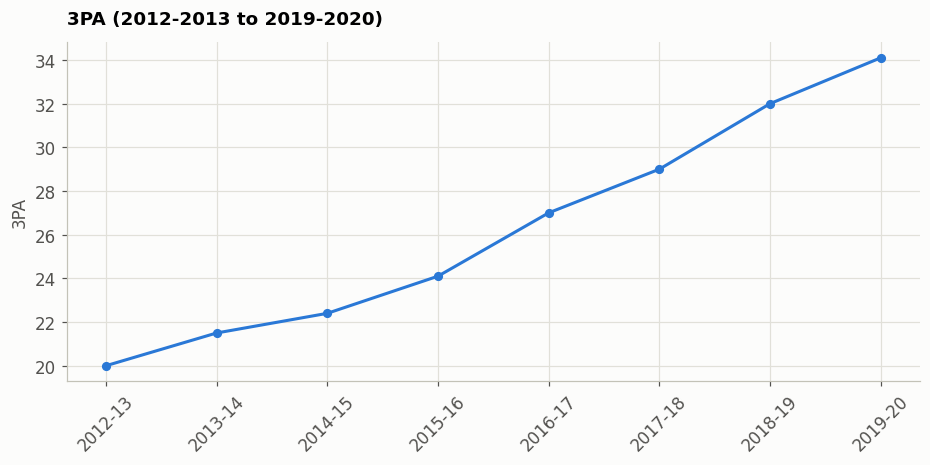

In [22]:
three_pa_era4 = league.iloc[::-1].reset_index(drop=True).iloc[33:41]
three_seasons4 = list(three_pa_era4["Season"])

print("Max:", three_pa_era4['3PA'].max())
print("Min:",three_pa_era4['3PA'].min())
print("Mean:", three_pa_era4['3PA'].mean())
print("Range:", three_pa_era4['3PA'].max()-three_pa_era4['3PA'].min())
three_pa_era4["diff"]=three_pa_era4["3PA"].diff()
print("Greatest Diff:",abs(three_pa_era4["diff"]).max())
print("Avg Diff:",abs(three_pa_era4["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons4)), three_pa_era4["3PA"], color=BLUE, marker="o", markersize=5
)
ax.set_title("3PA (2012-2013 to 2019-2020)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons4)))
ax.set_xticklabels(three_seasons4, rotation=45)
plt.show()

In [ ]:
three_pa_era4 = league.iloc[::-1].reset_index(drop=True).iloc[33:41]
three_seasons4 = list(three_pa_era4["Season"])

print("Max:", three_pa_era4['3PA'].max())
print("Min:",three_pa_era4['3PA'].min())
print("Mean:", three_pa_era4['3PA'].mean())
print("Range:", three_pa_era4['3PA'].max()-three_pa_era4['3PA'].min())
three_pa_era4["diff"]=three_pa_era4["3PA"].diff()
print("Greatest Diff:",abs(three_pa_era4["diff"]).max())
print("Avg Diff:",abs(three_pa_era4["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons4)), three_pa_era4["3PA"], color=BLUE, marker="o", markersize=5
)
ax.set_title("3PA (2012-2013 to 2019-2020)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons4)))
ax.set_xticklabels(three_seasons4, rotation=45)
plt.show()

Max: 34.1 New Max: 34.6
Min: 20.0 New Min: 18.4
Mean: 26.2625 New Mean: 26.309999999999995
Range: 14.100000000000001 New Range: 16.200000000000003
Greatest Diff: 3.0 New Greatest Diff: 3.0
Avg Diff: 2.0142857142857147 New Avg Diff: 1.8000000000000003


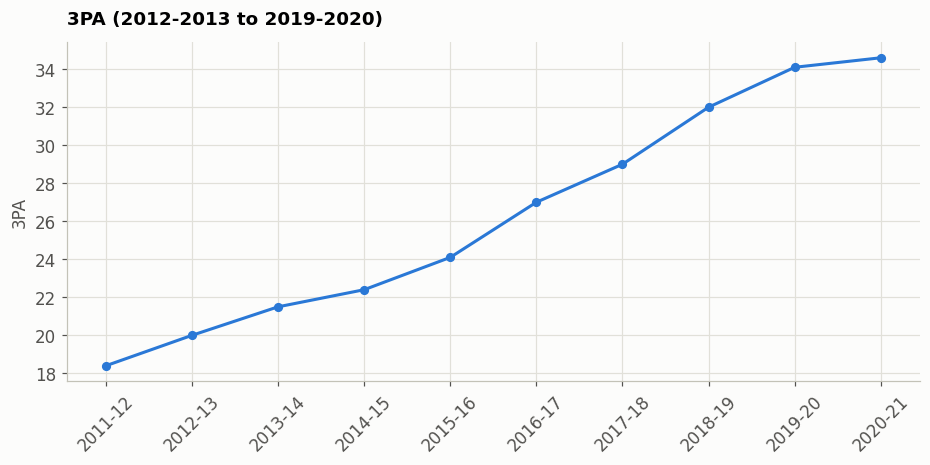

In [44]:
three_pa_era4_expanded = league.iloc[::-1].reset_index(drop=True).iloc[32:42]
three_seasons4_expanded = list(three_pa_era4_expanded["Season"])

print("Max:", three_pa_era4['3PA'].max(), "New Max:", three_pa_era4_expanded['3PA'].max())
print("Min:", three_pa_era4['3PA'].min(), "New Min:", three_pa_era4_expanded['3PA'].min())
print("Mean:", three_pa_era4['3PA'].mean(), "New Mean:", three_pa_era4_expanded['3PA'].mean())
print("Range:", three_pa_era4['3PA'].max() - three_pa_era4['3PA'].min(), "New Range:", three_pa_era4_expanded['3PA'].max() - three_pa_era4_expanded['3PA'].min())

three_pa_era4_expanded["diff"] = three_pa_era4_expanded["3PA"].diff()
print("Greatest Diff:", abs(three_pa_era4["diff"]).max(), "New Greatest Diff:", abs(three_pa_era4_expanded["diff"]).max())
print("Avg Diff:", abs(three_pa_era4["diff"]).mean(), "New Avg Diff:", abs(three_pa_era4_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons4_expanded)),
    three_pa_era4_expanded["3PA"],
    color=BLUE,
    marker="o",
    markersize=5
)
ax.set_title("3PA (2012-2013 to 2019-2020)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons4_expanded)))
ax.set_xticklabels(three_seasons4_expanded, rotation=45)
plt.show()

Max: 37.6
Min: 34.2
Mean: 35.61666666666667
Range: 3.3999999999999986
Greatest Diff: 2.5
Avg Diff: 1.1200000000000003


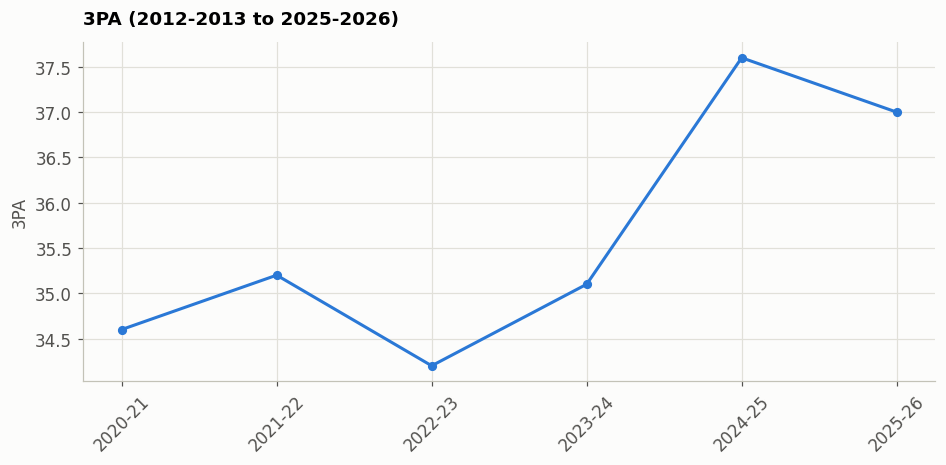

In [23]:
three_pa_era5 = league.iloc[::-1].reset_index(drop=True).iloc[41:]
three_seasons5 = list(three_pa_era5["Season"])

print("Max:", three_pa_era5['3PA'].max())
print("Min:",three_pa_era5['3PA'].min())
print("Mean:", three_pa_era5['3PA'].mean())
print("Range:", three_pa_era5['3PA'].max()-three_pa_era5['3PA'].min())
three_pa_era5["diff"]=three_pa_era5["3PA"].diff()
print("Greatest Diff:",abs(three_pa_era5["diff"]).max())
print("Avg Diff:",abs(three_pa_era5["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons5)), three_pa_era5["3PA"], color=BLUE, marker="o", markersize=5
)
ax.set_title("3PA (2012-2013 to 2025-2026)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons5)))
ax.set_xticklabels(three_seasons5, rotation=45)
plt.show()

Max: 37.6 New Max: 37.6
Min: 34.2 New Min: 32.0
Mean: 35.61666666666667 New Mean: 34.975
Range: 3.3999999999999986 New Range: 5.600000000000001
Greatest Diff: 2.5 New Greatest Diff: 2.5
Avg Diff: 1.1200000000000003 New Avg Diff: 1.171428571428572


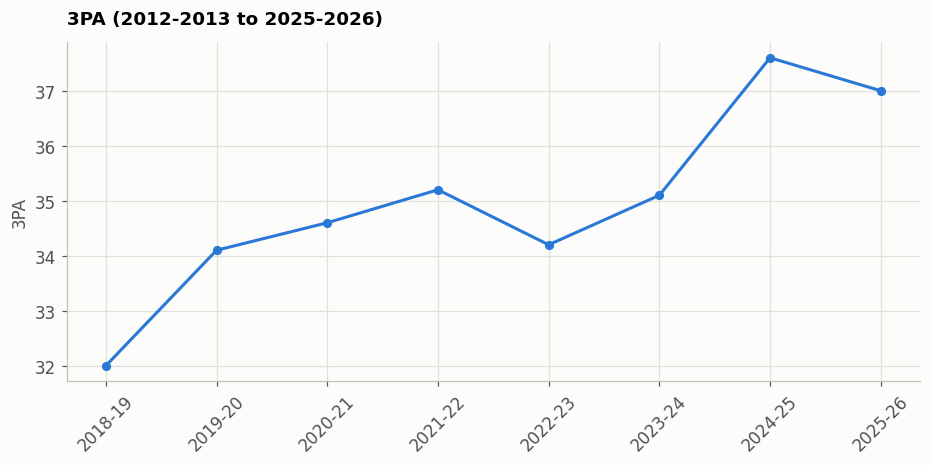

In [45]:
three_pa_era5_expanded = league.iloc[::-1].reset_index(drop=True).iloc[39:]
three_seasons5_expanded = list(three_pa_era5_expanded["Season"])

print("Max:", three_pa_era5['3PA'].max(), "New Max:", three_pa_era5_expanded['3PA'].max())
print("Min:", three_pa_era5['3PA'].min(), "New Min:", three_pa_era5_expanded['3PA'].min())
print("Mean:", three_pa_era5['3PA'].mean(), "New Mean:", three_pa_era5_expanded['3PA'].mean())
print("Range:", three_pa_era5['3PA'].max() - three_pa_era5['3PA'].min(), "New Range:", three_pa_era5_expanded['3PA'].max() - three_pa_era5_expanded['3PA'].min())

three_pa_era5_expanded["diff"] = three_pa_era5_expanded["3PA"].diff()
print("Greatest Diff:", abs(three_pa_era5["diff"]).max(), "New Greatest Diff:", abs(three_pa_era5_expanded["diff"]).max())
print("Avg Diff:", abs(three_pa_era5["diff"]).mean(), "New Avg Diff:", abs(three_pa_era5_expanded["diff"]).mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    range(len(three_seasons5_expanded)),
    three_pa_era5_expanded["3PA"],
    color=BLUE,
    marker="o",
    markersize=5
)
ax.set_title("3PA (2012-2013 to 2025-2026)", fontsize=12, pad=12)
ax.set_ylabel("3PA")
ax.set_xticks(range(len(three_seasons5_expanded)))
ax.set_xticklabels(three_seasons5_expanded, rotation=45)
plt.show()

Do any trends change during the playoffs?

In [46]:
playoffs = pd.read_csv("per_game_playoffs.csv", header=1)

# Filter columns using the corrected headers
league_playoffs = playoffs[['Season','Pace','PTS','3PA','ORtg','eFG%','FT/FGA']]


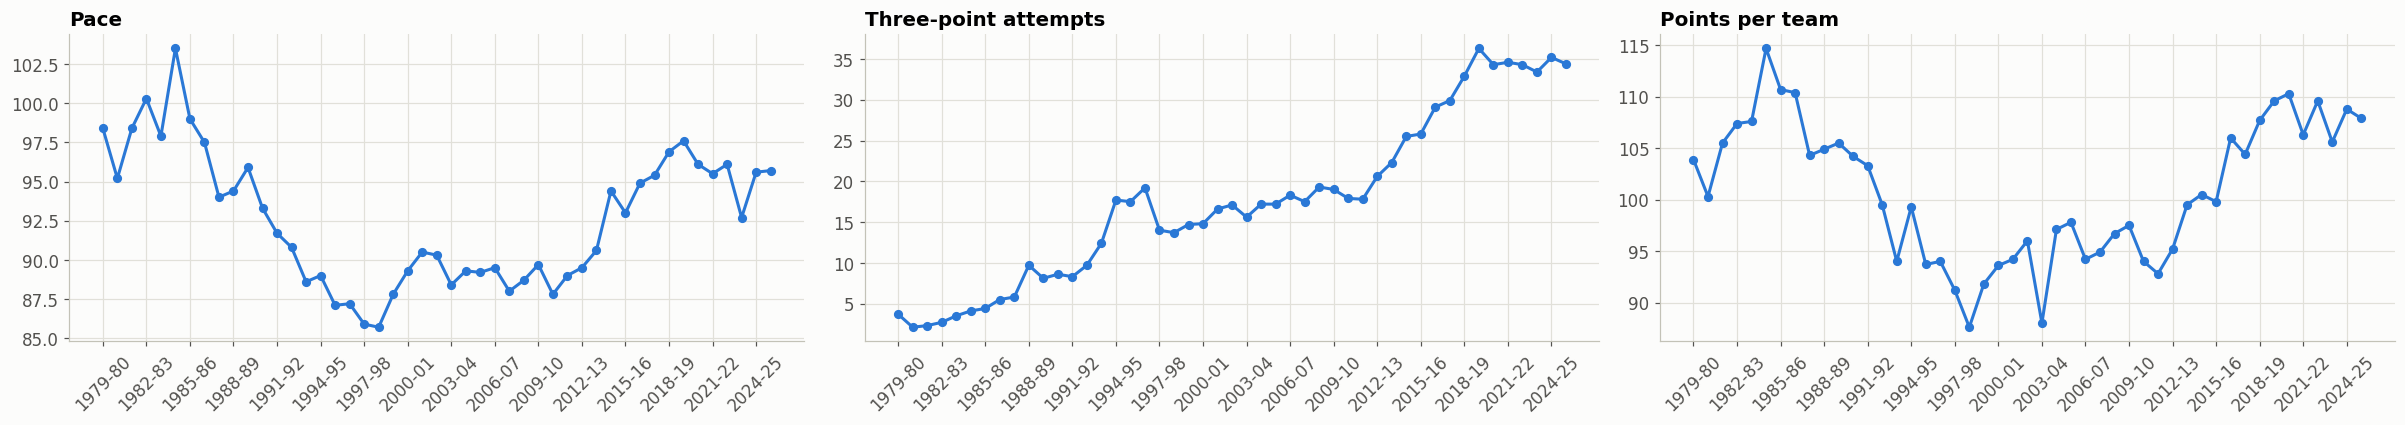

In [47]:
panels_playoffs = [("Pace", "Pace"), ("3PA", "Three-point attempts"), ("PTS", "Points per team")]
playoff_seasons = list(league_playoffs["Season"])[::-1]
reversed_league_playoffs = league_playoffs.iloc[::-1].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(22, 4))
for ax, (col, title) in zip(axes, panels):
    ax.plot(range(len(playoff_seasons)), reversed_league_playoffs[col], color=BLUE, marker="o", markersize=5)
    ax.set_title(title)
    ax.set_xticks(range(0, len(playoff_seasons), 3))
    ax.set_xticklabels(playoff_seasons[::3], rotation=45)
plt.tight_layout()
plt.show()

The three graphs in the playoffs maintain the same shape as the regular season, most notably the spike from 1994-1997